# The harmonium (notes Appendix B.1, fig:harmonium)

Each step follows the notes; equation labels are given in comments.

In [1]:
import sympy as sym
import circuit_quantization as cq
from circuit_quantization import Branch, Circuit, Loops, quantize, draw_circuit_diagram

sym.init_printing()
F, H, W = cq.ghz_to_farad, cq.ghz_to_henry, cq.phase_to_weber

In [2]:
circuit = Circuit([
    Branch("C", 1, 5, energy_symbols=True),
    Branch("J1", 1, 2, energy_symbols=True),
    Branch("J2", 1, 3, energy_symbols=True),
    Branch("J3", 4, 5, energy_symbols=True),
    Branch("L1", 2, 4, energy_symbols=True),
    Branch("L2", 3, 4, energy_symbols=True),
    Branch("L3", 4, 5, energy_symbols=True),
], ground=5)
EC, EC1, EJ1, EC2, EJ2, EC3, EJ3, EL1, EL2, EL3 = circuit.variables

In [3]:
EC

## Option 1: named physical loops

List the branches belonging to each loop. Incidence determines their relative
signs; the first branch has sign +1. Loop flux symbols are generated automatically,
with the capacitively broken loop explicitly set to zero.

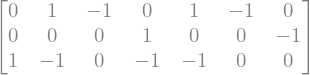

In [4]:
branch_dict = {  # eq:harm_G; first branch fixes the positive orientation
    "k": ("J1", "J2", "L1", "L2"),
    "f": ("J3", "L3"),
    "cb": ("C", "J1", "J3", "L1"),
}
loops = Loops(circuit, branch_dict, {"cb": 0})
vk, vf = loops.variables
loops.G

## Option 2: deterministic fundamental cycles

`from_circuit` selects a deterministic spanning tree and prints each signed loop and its flux.
`zero_capacitive=True` sets capacitively broken loop fluxes to zero;
use `Loops(circuit, branch_dict, fluxes=...)` for custom flux values.
Each loop is named after its closure branch, listed first with sign +1.
These default loop names and fluxes use their own basis. `rebase` below expresses
the physical fluxes from Option 1 in that basis, including the assumption that
`cb` has zero flux. Subsequent calculations continue to use `loops` from Option 1.

L2: +L2 -J1 +J2 -L1 [superconducting]; flux = Phi_L2
L3: +L3 -J3 [superconducting]; flux = Phi_L3
C: +C -J1 -J3 -L1 [capacitively broken]; flux = 0
Default flux symbols: (Phi_L2, Phi_L3)


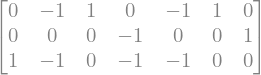

In [19]:
loops = Loops.from_circuit(circuit, zero_capacitive=True)
print("Default flux symbols:", loops.variables)
loops.G

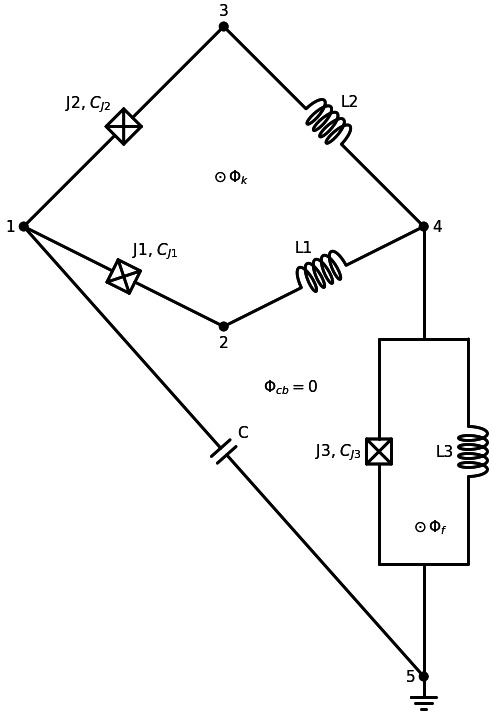

In [6]:
layout = {
    1: (-1, 1.25),
    2: (0, .75),
    3: (0, 2.25),
    4: (1, 1.25),
    5: (1, -1),
}
cq.draw_circuit_diagram(
    circuit, layout=layout,
    flux_labels={
        r"$\odot\,\Phi_k$": (0, 1.5),
        r"$\odot\,\Phi_f$": (1, -.25),
        r"$\Phi_{cb}=0$": (.3, .45),
    },
)

In [7]:

Z = sym.Matrix([[1, 0, 0, 0], [0, 1, 1, 1], [0, 1, -1, 1], [0, 1, 0, 0]])  # eq:harm_Z
res = quantize(circuit, loops, Z, ("c", "e", "e", "e"), simplify=True)
res

Result(circuit=Circuit(branches=(Branch(name='C', tail=1, head=5, C=e**2/(2*E_C*h), L=None, EJ=None, V=None, energy_symbols=True), Branch(name='J1', tail=1, head=2, C=e**2/(2*E_CJ1*h), L=None, EJ=E_J1, V=None, energy_symbols=True), Branch(name='J2', tail=1, head=3, C=e**2/(2*E_CJ2*h), L=None, EJ=E_J2, V=None, energy_symbols=True), Branch(name='J3', tail=4, head=5, C=e**2/(2*E_CJ3*h), L=None, EJ=E_J3, V=None, energy_symbols=True), Branch(name='L1', tail=2, head=4, C=0, L=Phi_0**2/(4*pi**2*E_L1*h), EJ=None, V=None, energy_symbols=True), Branch(name='L2', tail=3, head=4, C=0, L=Phi_0**2/(4*pi**2*E_L2*h), EJ=None, V=None, energy_symbols=True), Branch(name='L3', tail=4, head=5, C=0, L=Phi_0**2/(4*pi**2*E_L3*h), EJ=None, V=None, energy_symbols=True)), ground=5, t=t), loops=<circuit_quantization.circuit.Loops object at 0x1093b5050>, lag=Lagrangian(Omega=Matrix([
[ 1,  1,  1,  0,  0,  0,  0],
[ 0, -1,  0,  0,  1,  0,  0],
[ 0,  0, -1,  0,  0,  1,  0],
[ 0,  0,  0,  1, -1, -1,  1],
[-1,  0,  0,

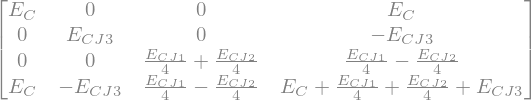

In [8]:
res.ham.E_C

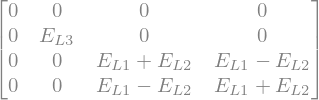

In [9]:
res.ham.E_L

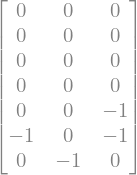

In [10]:
res.B

# Discover matching form

Start from the automatic mode basis, **without using the hand-written `Z` above**.
The target is the branch-phase structure of the notes' `eq:harm_H_dimless`.
We solve for the coordinate transformation, then enumerate all spanning trees
and identify those whose fundamental loops match the physical loops `k`, `f`,
and `cb` already defined above.

This is a constrained reconstruction of a specified Hamiltonian, not a blind
search for a unique canonical form. The physical flux assignment is an input:
changing a tree does not tell us which physical loop encloses zero flux.

Automatic types: ('c', 'e', 'e', 'h')


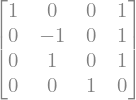

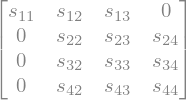

In [11]:
from IPython.display import display, Math

lag_auto = cq.lagrangian(circuit)
Z_auto, types_auto = cq.mode_basis(lag_auto)
auto_coords = cq.decouple(lag_auto, Z_auto, types_auto)
print("Automatic types:", auto_coords.types)
display(auto_coords.Z, cq.residual_freedom(auto_coords, keep_harmonic=False))

## 1. Select the residual transformation

The automatic basis has types `(c, e, e, h)`. The notes use `(c, e, e, e)`:
the harmonic direction is distributed across extended columns.
First promote the harmonic column by adding one extended column. Once that
column is extended, the residual pattern also permits compact components to
mix into it. This two-stage path respects `transform()`'s allowed pattern at
each step.

The target rows below are the coefficients of the three junction arguments
and three inductor phases, before external-flux offsets. Solving their linear
constraints determines the remaining transformation; no target `Z` is supplied.

Total S1, recovered Z, and final types:


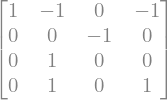

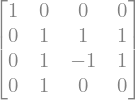

('c', 'e', 'e', 'e')


In [12]:
S_promote = sym.eye(auto_coords.Z.cols)
S_promote[auto_coords.types.index("e"), auto_coords.types.index("h")] = 1
mixed_coords = cq.transform(lag_auto, auto_coords, S_promote)
assert mixed_coords.types == ("c", "e", "e", "e")

S_pattern = cq.residual_freedom(mixed_coords, keep_harmonic=False)
WJ_target = sym.Matrix([  # J1, J2, J3
    [1, -1, -1, -1],
    [1, -1,  1, -1],
    [0,  1,  0,  0],
])
WL_target = sym.Matrix([  # L1, L2, L3
    [0, 0,  1, 1],
    [0, 0, -1, 1],
    [0, 1,  0, 0],
])
A = mixed_coords.omega_J_tilde.T.col_join(mixed_coords.omega_L_tilde.T)
unknowns = sorted(S_pattern.free_symbols, key=str)
solutions = sym.linsolve(list(A * S_pattern - WJ_target.col_join(WL_target)), unknowns)
assert len(solutions) == 1
S_match = S_pattern.subs(dict(zip(unknowns, next(iter(solutions)))))
assert not S_match.free_symbols.intersection(unknowns)
matched_coords = cq.transform(lag_auto, mixed_coords, S_match)
S1 = S_promote * S_match  # total transformation relative to the automatic basis
assert matched_coords.Z == auto_coords.Z * S1
assert matched_coords.omega_J_tilde.T == WJ_target
assert matched_coords.omega_L_tilde.T == WL_target
print("Total S1, recovered Z, and final types:")
display(S1, matched_coords.Z)
print(matched_coords.types)

## 2. Search spanning trees and loop matrices

For each spanning tree, construct its fundamental-cycle matrix $G_t$ and find
$T$ such that $G_t=T G_{\mathrm{physical}}$. Transform the flux vector with the
same $T$: $\Phi_t=T\Phi_{\mathrm{physical}}$.

Every candidate must satisfy $B_tT=B_{\mathrm{physical}}$. Thus all candidates
give the same branch offsets and Hamiltonian. To select a readable basis, keep
trees for which $T$ is a signed permutation: their loops are exactly `k`, `f`,
and `cb`, up to ordering and orientation. Do **not** independently zero a
capacitive loop in every tree; it may contain a nonzero physical flux.

In [13]:
reference_loops = loops
G_physical = sym.Matrix(reference_loops.G)
G_plus = G_physical.T * (G_physical * G_physical.T).inv()
B_physical = cq.irrotational_B(lag_auto, matched_coords, reference_loops)
candidates = []

for tree in cq.spanning_trees(circuit):
    tree_cycles = cq.fundamental_cycles(circuit, tree=tree)
    raw_loops = Loops(circuit, tree_cycles)
    T = raw_loops.G * G_plus
    tree_loops = reference_loops.rebase(raw_loops.G, names=raw_loops.names)
    B_tree = cq.irrotational_B(lag_auto, matched_coords, tree_loops)
    assert (B_tree * T - B_physical).applyfunc(sym.cancel).is_zero_matrix
    same_loops = (
        all(sum(abs(x) for x in T.row(i)) == 1 for i in range(T.rows))
        and all(sum(abs(x) for x in T.col(j)) == 1 for j in range(T.cols))
    )
    candidates.append(dict(tree=tree, loops=tree_loops, T=T, B=B_tree, match=same_loops))

matches = [candidate for candidate in candidates if candidate["match"]]
assert matches, "No fundamental-cycle basis matches the requested physical loops"
print(f"Checked {len(candidates)} spanning trees; all preserve the branch flux offsets.")
print(f"{len(matches)} trees match the physical loop basis up to signs and ordering:")
for candidate in matches:
    print(candidate["tree"])

Checked 20 spanning trees; all preserve the branch flux offsets.
2 trees match the physical loop basis up to signs and ordering:
('J1', 'J2', 'J3', 'L1')
('J1', 'J3', 'L1', 'L2')


Selected tree: ('J1', 'J2', 'J3', 'L1')
G columns: ('C', 'J1', 'J2', 'J3', 'L1', 'L2', 'L3')
G rows (closure branches): ('L2', 'L3', 'C')
G_tree, T, and its correctly transformed flux vector:


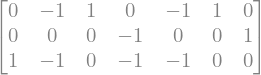

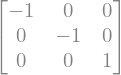

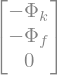

In [14]:
chosen = matches[0]
print("Selected tree:", chosen["tree"])
print("G columns:", circuit.branch_names)
print("G rows (closure branches):", chosen["loops"].names)
print("G_tree, T, and its correctly transformed flux vector:")
display(chosen["loops"].G, chosen["T"], chosen["loops"].Phi_ext)
# Relabeling/reorienting the selected rows recovers exactly the physical G.
assert chosen["T"].inv() * chosen["loops"].G == G_physical

## 3. Verify the Hamiltonian

Build the Hamiltonian directly from the recovered coordinates and selected tree
basis. The notes complete the inductive squares, whereas the implementation
drops flux-only additive terms. Their difference must therefore be exactly
$\tfrac12 E_{L_2}\varphi_k^2+\tfrac12 E_{L_3}\varphi_f^2$ and contain no dynamical
variables. Fluxes supplied in webers are converted to dimensionless phases here.
The target expression below is only an independent check. The displayed result
is rebuilt by `quantize()` from the recovered basis and loop assignment.

In [15]:
reconstructed = cq.quantize(
    circuit, chosen["loops"], matched_coords.Z, matched_coords.types, simplify=True,
)
found_ham = reconstructed.ham
p1, p2, p3, p4 = found_ham.varphi
n1, n2, n3, n4 = found_ham.n
ng = found_ham.n_g[0]
phase_k = cq.weber_to_phase(reference_loops.Phi_ext[reference_loops.names.index("k")])
phase_f = cq.weber_to_phase(reference_loops.Phi_ext[reference_loops.names.index("f")])
EC_bar, EC_delta = (EC1 + EC2) / 2, (EC1 - EC2) / 2
H_target = (
    4*EC*(n1 + n4 - ng)**2 + 4*EC3*(n2 - n4)**2
    + 2*EC_bar*(n3**2 + n4**2) + 4*EC_delta*n3*n4
    + EL1/2*(p3 + p4)**2
    + EL2/2*(p4 - p3 - phase_k)**2 + EL3/2*(p2 - phase_f)**2
    - EJ1*sym.cos(p1 - p2 - p3 - p4)
    - EJ2*sym.cos(p1 - p2 + p3 - p4) - EJ3*sym.cos(p2)
)
flux_constant = EL2*phase_k**2/2 + EL3*phase_f**2/2
assert sym.simplify(sym.expand(found_ham.H + flux_constant - H_target)) == 0
print("Verified: recovered Hamiltonian + flux-only constant = target Hamiltonian.")
display(reconstructed)

Verified: recovered Hamiltonian + flux-only constant = target Hamiltonian.


Result(circuit=Circuit(branches=(Branch(name='C', tail=1, head=5, C=e**2/(2*E_C*h), L=None, EJ=None, V=None, energy_symbols=True), Branch(name='J1', tail=1, head=2, C=e**2/(2*E_CJ1*h), L=None, EJ=E_J1, V=None, energy_symbols=True), Branch(name='J2', tail=1, head=3, C=e**2/(2*E_CJ2*h), L=None, EJ=E_J2, V=None, energy_symbols=True), Branch(name='J3', tail=4, head=5, C=e**2/(2*E_CJ3*h), L=None, EJ=E_J3, V=None, energy_symbols=True), Branch(name='L1', tail=2, head=4, C=0, L=Phi_0**2/(4*pi**2*E_L1*h), EJ=None, V=None, energy_symbols=True), Branch(name='L2', tail=3, head=4, C=0, L=Phi_0**2/(4*pi**2*E_L2*h), EJ=None, V=None, energy_symbols=True), Branch(name='L3', tail=4, head=5, C=0, L=Phi_0**2/(4*pi**2*E_L3*h), EJ=None, V=None, energy_symbols=True)), ground=5, t=t), loops=<circuit_quantization.circuit.Loops object at 0x11fc399d0>, lag=Lagrangian(Omega=Matrix([
[ 1,  1,  1,  0,  0,  0,  0],
[ 0, -1,  0,  0,  1,  0,  0],
[ 0,  0, -1,  0,  0,  1,  0],
[ 0,  0,  0,  1, -1, -1,  1],
[-1,  0,  0,